# Урок 10. Обработка видео и FastAPI

> **Про задание.** К этой теме в MyStat приложен только архив с материалами
> урока — четыре примера: чтение видео, извлечение кадров, обработка видео и
> детекция движения. Текста задания нет. Объём работы определён по этим
> материалам и по названию темы: те же четыре операции оформлены как модуль
> `video_tools.py` и подняты сервисом FastAPI (`api.py`).

> **Про видео.** Исходный файл к уроку не приложен, поэтому тестовое видео
> генерируется скриптом `make_video.py`: 120 кадров, 20 fps, 480x320, с
> движущимся прямоугольником, летающим кругом и объектом, появляющимся в
> середине ролика.

In [1]:
import cv2
import matplotlib.pyplot as plt
import pandas as pd

import video_tools as vt
from make_video import build

pd.set_option("display.width", 120)

path, total = build("sample.mp4")
print(f"Видео готово: {path}, кадров {total}")


def show(image_bgr, title, size=(7, 5)):
    plt.figure(figsize=size)
    plt.imshow(cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

Видео готово: sample.mp4, кадров 120


## 1. Чтение видео и его характеристики

`cv2.imshow` в ноутбуке не работает — окна операционной системы здесь нет,
поэтому кадры показываются через matplotlib.

In [2]:
info = vt.video_info("sample.mp4")
pd.DataFrame([info])

,fps,width,height,frame_count,duration_sec
0,20.0,480,320,120,6.0


Кадр прочитан: True | форма массива: (320, 480, 3)


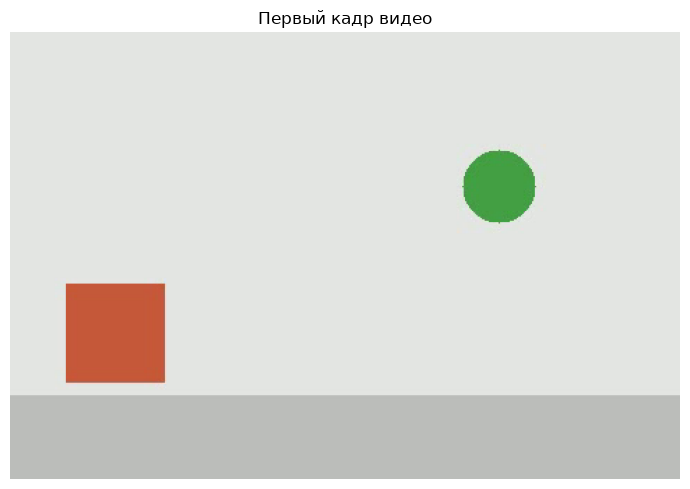

In [3]:
cap = cv2.VideoCapture("sample.mp4")
ok, first_frame = cap.read()
cap.release()

print("Кадр прочитан:", ok, "| форма массива:", first_frame.shape)
show(first_frame, "Первый кадр видео")

## 2. Извлечение кадров

Сохраняется каждый двадцатый кадр: при 20 fps это один кадр в секунду.

In [4]:
frames = vt.extract_frames("sample.mp4", "frames", every=20)
print(f"Сохранено кадров: {len(frames)}")
for name in frames:
    print(" ", name)

Сохранено кадров: 6
  frames/frame_000.jpg
  frames/frame_001.jpg
  frames/frame_002.jpg
  frames/frame_003.jpg
  frames/frame_004.jpg
  frames/frame_005.jpg


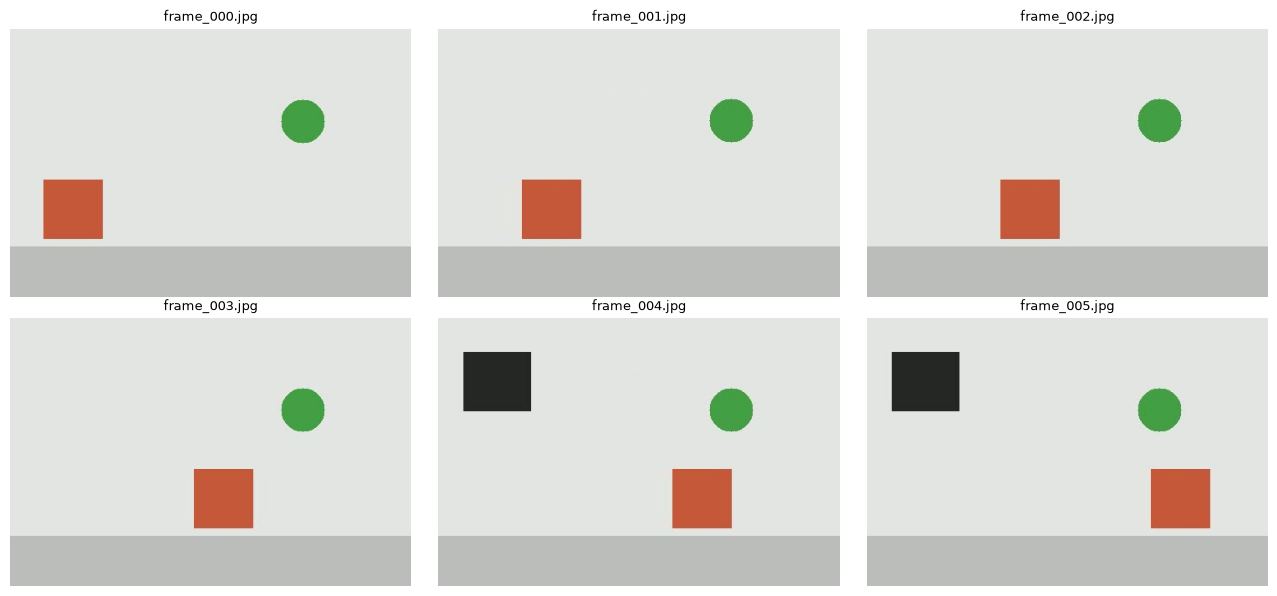

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6))

for ax, name in zip(axes.ravel(), frames):
    ax.imshow(cv2.cvtColor(cv2.imread(name), cv2.COLOR_BGR2RGB))
    ax.set_title(name.split("/")[-1], fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

По кадрам видно движение: прямоугольник уезжает слева направо, круг описывает
дугу, а тёмный квадрат появляется только во второй половине ролика.

## 3. Обработка видео: выделение границ

Каждый кадр переводится в градации серого, размывается и прогоняется через Canny.
Результат записывается в новый файл.

In [6]:
result = vt.process_edges("sample.mp4", "processed_edges.mp4")
print(result)

{'output': 'processed_edges.mp4', 'frames': 120}


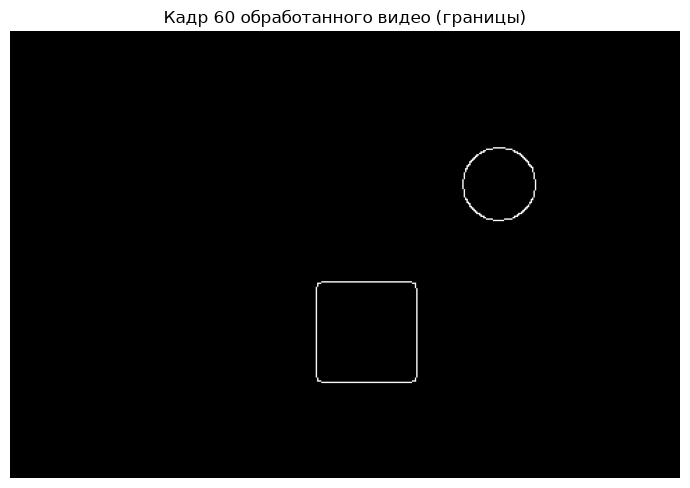

In [7]:
cap = cv2.VideoCapture("processed_edges.mp4")
cap.set(cv2.CAP_PROP_POS_FRAMES, 60)
ok, edges_frame = cap.read()
cap.release()

show(edges_frame, "Кадр 60 обработанного видео (границы)")

## 4. Детекция движения

Используется вычитание фона `MOG2`: алгоритм накапливает модель неподвижного
фона и отмечает пиксели, которые от неё отличаются. Затем маска чистится
морфологией, и по контурам строятся рамки.

In [8]:
motion = vt.detect_motion("sample.mp4", min_area=600)
print(f"Всего кадров:        {motion['total_frames']}")
print(f"Кадров с движением:  {motion['frames_with_motion']}")

events = pd.DataFrame(motion["events"])
events.head(10)

Всего кадров:        120
Кадров с движением:  120


,frame,objects,area
0,0,1,153600
1,1,1,5016
2,2,1,5624
3,3,2,4488
4,4,1,3240
5,5,1,3224
6,6,1,3224
7,7,1,3224
8,8,1,3180
9,9,1,3364


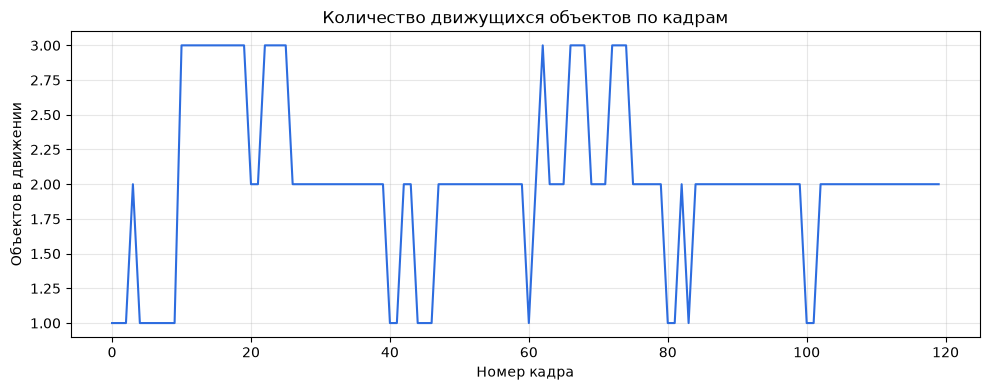

In [9]:
plt.figure(figsize=(10, 4))
plt.plot(events["frame"], events["objects"], color="#2d6cdf")
plt.xlabel("Номер кадра")
plt.ylabel("Объектов в движении")
plt.title("Количество движущихся объектов по кадрам")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

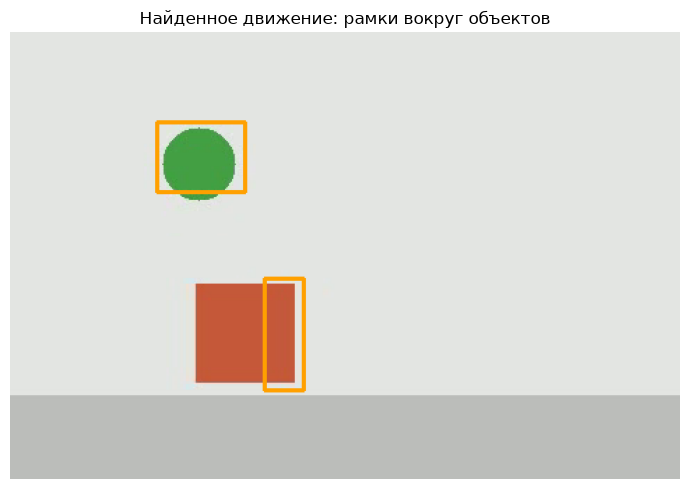

In [10]:
if motion["preview"] is not None:
    show(motion["preview"], "Найденное движение: рамки вокруг объектов")

## Вывод

Четыре операции над видео сводятся к одному и тому же приёму: видео — это
последовательность обычных изображений, и каждый кадр обрабатывается теми же
методами, что и фотография в предыдущем уроке. Разница лишь в том, что кадры
нужно читать в цикле и не забывать освобождать ресурс через `release()`.

Детекция движения показала движение практически во всех кадрах, и это ожидаемо:
в сгенерированном ролике объекты двигаются непрерывно с первого кадра. На
реальном видео с неподвижными участками график был бы рваным, и по нему можно
было бы находить моменты активности.

Важная деталь про `MOG2`: алгоритму нужно несколько десятков кадров, чтобы
построить модель фона. В самом начале ролика он отмечает как движение почти всё
подряд, поэтому превью берётся после тридцатого кадра, когда фон уже выучен.

Все четыре операции вынесены в модуль `video_tools.py` и доступны через FastAPI:
файл загружается на сервер, обрабатывается и результат возвращается в JSON.